1 – Project Introduction

In [ ]:
# Customer Segmentation & Service Recommendation System
#
# Objective:
# Group customers based on behavior, interests, engagement,
# spending and service interaction patterns.
#
# Apply K-Means clustering and PCA for customer segmentation.
# Build a recommendation system for suitable learning programs
# and technology services.
#
# Dataset: Synthetic Customer Dataset

2 – Import Libraries

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


3 – Create Customer Dataset

In [2]:
# Generate a sample customer dataset for analysis
# This is synthetic data, not actual Veda customer information.

np.random.seed(42)

n = 500

interests = [
    "Data Science",
    "Web Development",
    "AI and ML",
    "Python Programming",
    "Cloud Computing"
]

customer_data = pd.DataFrame({
    "Customer_ID": range(1, n + 1),
    "Age": np.random.randint(18, 55, n),
    "Interest": np.random.choice(interests, n),
    "Engagement_Score": np.random.randint(1, 101, n),
    "Service_Inquiries": np.random.randint(0, 16, n),
    "Monthly_Spending": np.random.randint(500, 15001, n),
    "Interactions": np.random.randint(1, 51, n),
    "Course_Completion_Rate": np.random.randint(0, 101, n)
})

display(customer_data.head())

print("Dataset Shape:", customer_data.shape)

,Customer_ID,Age,Interest,Engagement_Score,Service_Inquiries,Monthly_Spending,Interactions,Course_Completion_Rate
0,1,46,Cloud Computing,28,6,1119,12,56
1,2,32,Data Science,85,9,1774,32,36
2,3,25,Python Programming,49,9,1456,32,57
3,4,38,Data Science,71,15,2439,28,20
4,5,36,Data Science,81,10,4453,13,81


Dataset Shape: (500, 8)


4 – Dataset Overview

In [3]:
# Understand customer dataset structure

print("Dataset Information:")
customer_data.info()

print("\nStatistical Summary:")
display(customer_data.describe())

print("\nColumn Names:")
print(customer_data.columns.tolist())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Customer_ID             500 non-null    int64 
 1   Age                     500 non-null    int64 
 2   Interest                500 non-null    object
 3   Engagement_Score        500 non-null    int64 
 4   Service_Inquiries       500 non-null    int64 
 5   Monthly_Spending        500 non-null    int64 
 6   Interactions            500 non-null    int64 
 7   Course_Completion_Rate  500 non-null    int64 
dtypes: int64(7), object(1)
memory usage: 31.4+ KB

Statistical Summary:


,Customer_ID,Age,Engagement_Score,Service_Inquiries,Monthly_Spending,Interactions,Course_Completion_Rate
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,250.500000,37.066000,51.044000,7.676000,7928.732000,25.640000,49.604000
std,144.481833,10.976092,29.252923,4.685182,4122.256222,13.985764,28.787647
min,1.000000,18.000000,1.000000,0.000000,509.000000,1.000000,0.000000
25%,125.750000,28.000000,26.000000,3.000000,4589.500000,14.000000,25.000000
50%,250.500000,38.500000,51.000000,8.000000,7885.000000,25.000000,48.000000
75%,375.250000,46.000000,77.000000,12.000000,11429.250000,37.000000,74.000000
max,500.000000,54.000000,100.000000,15.000000,14994.000000,50.000000,100.000000



Column Names:
['Customer_ID', 'Age', 'Interest', 'Engagement_Score', 'Service_Inquiries', 'Monthly_Spending', 'Interactions', 'Course_Completion_Rate']


5 – Data Cleaning

In [4]:
# Check and handle missing values and duplicate records

print("Missing Values Before Cleaning:")
print(customer_data.isnull().sum())

print("\nDuplicate Records:",
      customer_data.duplicated().sum())

customer_data = customer_data.drop_duplicates()

# Fill missing numerical values with median
numeric_columns = customer_data.select_dtypes(
    include=np.number
).columns

for col in numeric_columns:
    customer_data[col] = customer_data[col].fillna(
        customer_data[col].median()
    )

# Fill missing categorical values with mode
customer_data["Interest"] = customer_data["Interest"].fillna(
    customer_data["Interest"].mode()[0]
)

print("\nData cleaning completed!")
print("Remaining Missing Values:",
      customer_data.isnull().sum().sum())

Missing Values Before Cleaning:
Customer_ID               0
Age                       0
Interest                  0
Engagement_Score          0
Service_Inquiries         0
Monthly_Spending          0
Interactions              0
Course_Completion_Rate    0
dtype: int64

Duplicate Records: 0

Data cleaning completed!
Remaining Missing Values: 0


6 – Customer Behavior Analysis

In [5]:
# Analyze customer behavior and engagement

print("Average Customer Age:",
      round(customer_data["Age"].mean(), 2))

print("\nAverage Engagement Score:",
      round(customer_data["Engagement_Score"].mean(), 2))

print("\nAverage Monthly Spending:",
      round(customer_data["Monthly_Spending"].mean(), 2))

print("\nAverage Service Inquiries:",
      round(customer_data["Service_Inquiries"].mean(), 2))

print("\nCustomer Interests:")
display(customer_data["Interest"].value_counts())

print("\nAverage Course Completion Rate:",
      round(customer_data["Course_Completion_Rate"].mean(), 2), "%")

Average Customer Age: 37.07

Average Engagement Score: 51.04

Average Monthly Spending: 7928.73

Average Service Inquiries: 7.68

Customer Interests:


,count
Interest,
Data Science,107
Cloud Computing,106
AI and ML,100
Web Development,94
Python Programming,93



Average Course Completion Rate: 49.6 %


7 – Customer Interest Visualization

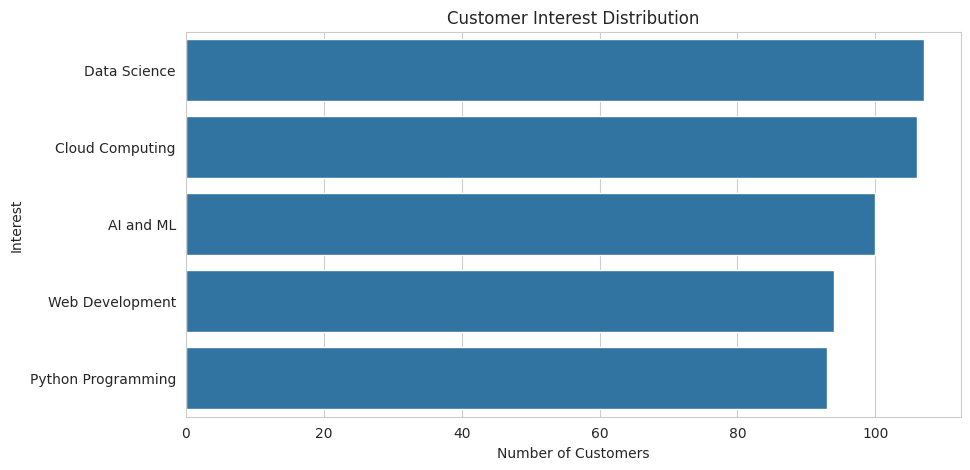

In [6]:
# Visualize customer interests

plt.figure(figsize=(10, 5))

sns.countplot(
    data=customer_data,
    y="Interest",
    order=customer_data["Interest"].value_counts().index
)

plt.title("Customer Interest Distribution")
plt.xlabel("Number of Customers")
plt.ylabel("Interest")
plt.show()

8 – Feature Engineering

In [7]:
# Create additional features for better customer analysis

customer_data["Engagement_Level"] = pd.cut(
    customer_data["Engagement_Score"],
    bins=[0, 35, 70, 100],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

customer_data["Spending_Level"] = pd.cut(
    customer_data["Monthly_Spending"],
    bins=[0, 5000, 10000, 15000],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

customer_data["Interaction_Rate"] = (
    customer_data["Interactions"] /
    (customer_data["Service_Inquiries"] + 1)
)

print("Feature engineering completed!")

display(customer_data.head())

Feature engineering completed!


,Customer_ID,Age,Interest,Engagement_Score,Service_Inquiries,Monthly_Spending,Interactions,Course_Completion_Rate,Engagement_Level,Spending_Level,Interaction_Rate
0,1,46,Cloud Computing,28,6,1119,12,56,Low,Low,1.714286
1,2,32,Data Science,85,9,1774,32,36,High,Low,3.200000
2,3,25,Python Programming,49,9,1456,32,57,Medium,Low,3.200000
3,4,38,Data Science,71,15,2439,28,20,High,Low,1.750000
4,5,36,Data Science,81,10,4453,13,81,High,Low,1.181818


9 – Prepare Features for Clustering

In [8]:
# Select numerical features for K-Means clustering

features = [
    "Age",
    "Engagement_Score",
    "Service_Inquiries",
    "Monthly_Spending",
    "Interactions",
    "Course_Completion_Rate",
    "Interaction_Rate"
]

X = customer_data[features]

# Standardization brings features to a comparable scale
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature scaling completed!")
print("Scaled Data Shape:", X_scaled.shape)

Feature scaling completed!
Scaled Data Shape: (500, 7)


10 – Find Optimal Number of Clusters

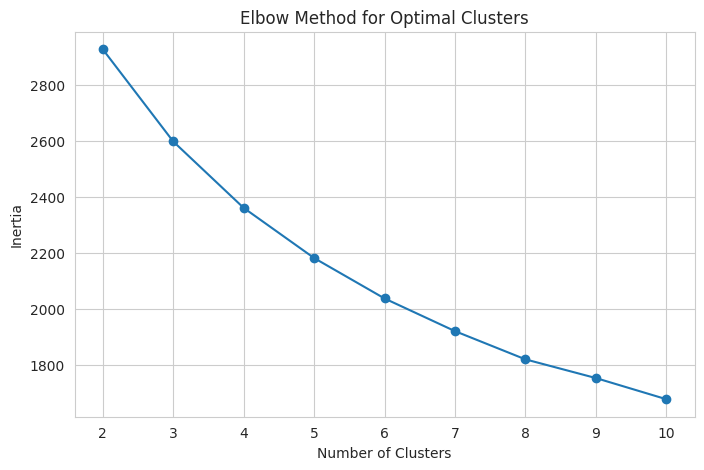

In [9]:
# Use the Elbow Method to find a suitable cluster count

inertia_values = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), inertia_values, marker="o")

plt.title("Elbow Method for Optimal Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(range(2, 11))
plt.show()

11 – Apply K-Means Clustering

In [10]:
# Group customers into four behavior-based clusters
# K-Means is an unsupervised learning algorithm.

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

customer_data["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")

print("\nCustomers in Each Cluster:")
print(customer_data["Cluster"].value_counts().sort_index())

display(customer_data.head())

K-Means clustering completed!

Customers in Each Cluster:
Cluster
0    137
1     64
2    136
3    163
Name: count, dtype: int64


,Customer_ID,Age,Interest,Engagement_Score,Service_Inquiries,Monthly_Spending,Interactions,Course_Completion_Rate,Engagement_Level,Spending_Level,Interaction_Rate,Cluster
0,1,46,Cloud Computing,28,6,1119,12,56,Low,Low,1.714286,2
1,2,32,Data Science,85,9,1774,32,36,High,Low,3.200000,3
2,3,25,Python Programming,49,9,1456,32,57,Medium,Low,3.200000,0
3,4,38,Data Science,71,15,2439,28,20,High,Low,1.750000,3
4,5,36,Data Science,81,10,4453,13,81,High,Low,1.181818,2


12 – Evaluate Clusters

In [11]:
# Silhouette Score measures how well-separated the clusters are.
# A higher score generally indicates better-defined clusters.

score = silhouette_score(X_scaled, customer_data["Cluster"])

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.137


13 – PCA Visualization

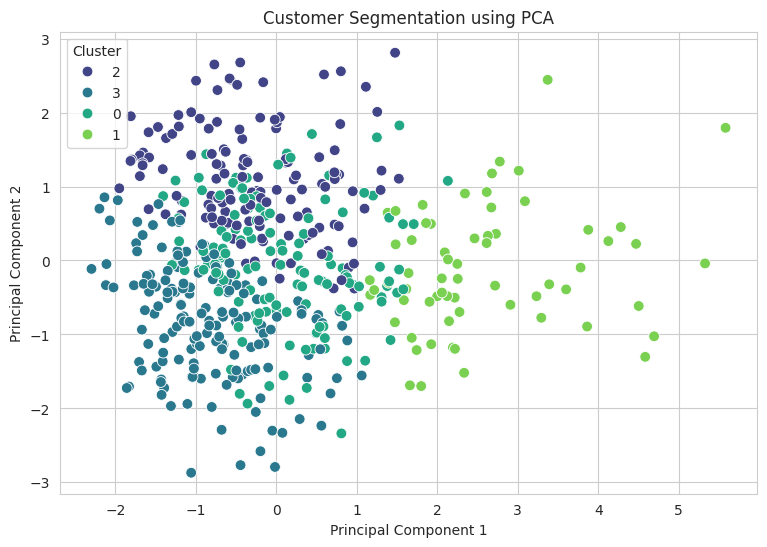

Explained Variance Ratio: [0.25123465 0.16510178]


In [12]:
# Reduce multiple features into two dimensions for visualization

pca = PCA(n_components=2)

pca_data = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    pca_data,
    columns=["Principal Component 1", "Principal Component 2"]
)

pca_df["Cluster"] = customer_data["Cluster"].astype(str)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x="Principal Component 1",
    y="Principal Component 2",
    hue="Cluster",
    palette="viridis",
    s=60
)

plt.title("Customer Segmentation using PCA")
plt.show()

print("Explained Variance Ratio:",
      pca.explained_variance_ratio_)

l 14 – Customer Segment Profiles

In [13]:
# Analyze the average behavior of customers in each cluster

segment_profiles = customer_data.groupby("Cluster")[features].mean().round(2)

print("Customer Segment Profiles:")
display(segment_profiles)

Customer Segment Profiles:


,Age,Engagement_Score,Service_Inquiries,Monthly_Spending,Interactions,Course_Completion_Rate,Interaction_Rate
Cluster,,,,,,,
0,42.28,42.90,9.20,6718.64,36.86,64.76,4.20
1,39.22,53.16,1.31,7729.69,35.64,36.12,19.10
2,32.68,39.28,5.02,7735.20,13.44,62.27,3.30
3,35.50,66.88,11.10,9185.44,22.46,31.59,2.09


15 – Customer Segment Names

In [14]:
# Give meaningful labels to clusters based on their behavior.
# These labels are derived from cluster averages.

cluster_order = segment_profiles.sort_values(
    "Engagement_Score"
).index.tolist()

segment_names = [
    "Low Engagement Customers",
    "Developing Customers",
    "Active Customers",
    "Highly Engaged Customers"
]

segment_mapping = dict(zip(cluster_order, segment_names))

customer_data["Customer_Segment"] = (
    customer_data["Cluster"].map(segment_mapping)
)

print("Customer Segments:")
display(
    customer_data[
        ["Customer_ID", "Interest", "Cluster", "Customer_Segment"]
    ].head(10)
)

Customer Segments:


,Customer_ID,Interest,Cluster,Customer_Segment
0,1,Cloud Computing,2,Low Engagement Customers
1,2,Data Science,3,Highly Engaged Customers
2,3,Python Programming,0,Developing Customers
3,4,Data Science,3,Highly Engaged Customers
4,5,Data Science,2,Low Engagement Customers
5,6,Cloud Computing,0,Developing Customers
6,7,Python Programming,3,Highly Engaged Customers
7,8,Python Programming,2,Low Engagement Customers
8,9,Python Programming,3,Highly Engaged Customers
9,10,AI and ML,1,Active Customers


16 – Service Recommendation Logic

In [15]:
# Recommend services based on customer interest and engagement.
# These are example recommendations, not an official Veda service catalog.

def recommend_service(row):

    interest_recommendations = {
        "Data Science": "Data Science Training Program",
        "Web Development": "Full Stack Web Development Program",
        "AI and ML": "Artificial Intelligence and ML Program",
        "Python Programming": "Advanced Python Programming Course",
        "Cloud Computing": "Cloud Computing Fundamentals"
    }

    recommendation = interest_recommendations[row["Interest"]]

    if row["Engagement_Score"] < 35:
        return "Beginner Learning Program + " + recommendation

    elif row["Course_Completion_Rate"] > 75:
        return "Advanced Learning Program + " + recommendation

    elif row["Service_Inquiries"] > 10:
        return "Personalized Service Consultation + " + recommendation

    else:
        return "Recommended Learning Program: " + recommendation


customer_data["Recommended_Service"] = customer_data.apply(
    recommend_service,
    axis=1
)

print("Service recommendations generated!")

display(
    customer_data[
        [
            "Customer_ID",
            "Interest",
            "Customer_Segment",
            "Recommended_Service"
        ]
    ].head(15)
)

Service recommendations generated!


,Customer_ID,Interest,Customer_Segment,Recommended_Service
0,1,Cloud Computing,Low Engagement Customers,Beginner Learning Program + Cloud Computing Fu...
1,2,Data Science,Highly Engaged Customers,Recommended Learning Program: Data Science Tra...
2,3,Python Programming,Developing Customers,Recommended Learning Program: Advanced Python ...
3,4,Data Science,Highly Engaged Customers,Personalized Service Consultation + Data Scien...
4,5,Data Science,Low Engagement Customers,Advanced Learning Program + Data Science Train...
5,6,Cloud Computing,Developing Customers,Recommended Learning Program: Cloud Computing ...
6,7,Python Programming,Highly Engaged Customers,Personalized Service Consultation + Advanced P...
7,8,Python Programming,Low Engagement Customers,Beginner Learning Program + Advanced Python Pr...
8,9,Python Programming,Highly Engaged Customers,Advanced Learning Program + Advanced Python Pr...
9,10,AI and ML,Active Customers,Recommended Learning Program: Artificial Intel...


17 – Recommendation Analysis

Recommendation Summary:


,count
Recommended_Service,
Beginner Learning Program + Data Science Training Program,41
Recommended Learning Program: Cloud Computing Fundamentals,39
Beginner Learning Program + Artificial Intelligence and ML Program,37
Recommended Learning Program: Advanced Python Programming Course,33
Beginner Learning Program + Advanced Python Programming Course,32
Recommended Learning Program: Full Stack Web Development Program,30
Beginner Learning Program + Full Stack Web Development Program,29
Recommended Learning Program: Data Science Training Program,28
Recommended Learning Program: Artificial Intelligence and ML Program,28


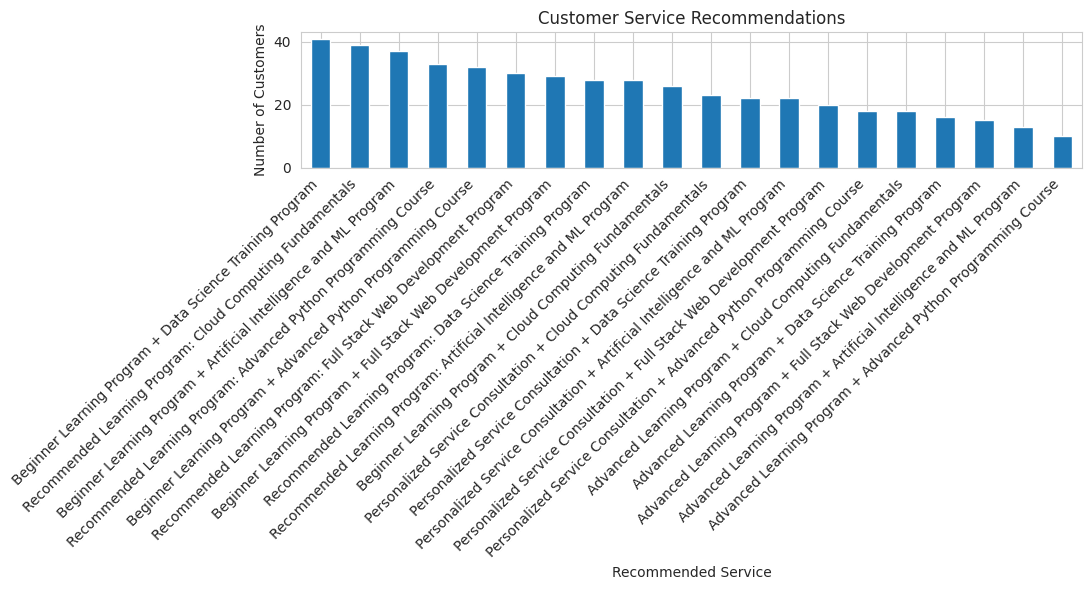

In [16]:
# Count recommendations given to customers

recommendation_counts = (
    customer_data["Recommended_Service"].value_counts()
)

print("Recommendation Summary:")
display(recommendation_counts)

plt.figure(figsize=(11, 6))

recommendation_counts.plot(kind="bar")

plt.title("Customer Service Recommendations")
plt.xlabel("Recommended Service")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

18 – Key Findings

In [17]:
# Summarize important findings from the project

print("CUSTOMER SEGMENTATION – KEY FINDINGS")

print("\n1. Total Customers:", len(customer_data))

print("\n2. Number of Customer Segments:",
      customer_data["Cluster"].nunique())

print("\n3. Customer Distribution:")
print(customer_data["Customer_Segment"].value_counts())

print("\n4. Average Monthly Spending:",
      round(customer_data["Monthly_Spending"].mean(), 2))

print("\n5. Most Common Customer Interest:",
      customer_data["Interest"].mode()[0])

print("\n6. Average Engagement Score:",
      round(customer_data["Engagement_Score"].mean(), 2))

print("\n7. Silhouette Score:", round(score, 3))

print("\n8. Most Common Recommendation:")
print(recommendation_counts.index[0])

CUSTOMER SEGMENTATION – KEY FINDINGS

1. Total Customers: 500

2. Number of Customer Segments: 4

3. Customer Distribution:
Customer_Segment
Highly Engaged Customers    163
Developing Customers        137
Low Engagement Customers    136
Active Customers             64
Name: count, dtype: int64

4. Average Monthly Spending: 7928.73

5. Most Common Customer Interest: Data Science

6. Average Engagement Score: 51.04

7. Silhouette Score: 0.137

8. Most Common Recommendation:
Beginner Learning Program + Data Science Training Program
